# TUGAS MANDIRI PRAKTIKUM BIG DATA — PERTEMUAN 14
## Unsupervised Learning: Segmentasi Menu dengan K-Means Clustering

| Informasi | Detail |
|---|---|
| **Mata Kuliah** | Praktikum Big Data |
| **Pertemuan** | 14 (Tugas Mandiri) |
| **Nama Mahasiswa** | Yarsya |
| **NPM** | 2505060066 |
| **Program Studi** | S1 Teknologi Informasi — Universitas Tidar |

---

### Skenario Tugas
Tim dapur dan marketing **"Kopi Nusantara"** ingin mengelompokkan 60 menu di katalog mereka berdasarkan karakteristik **harga** dan **popularitas (`rata_rata_pesanan_harian`)** menggunakan algoritma *unsupervised learning* **K-Means Clustering** di PySpark MLlib. Hasil segmentasi ini digunakan untuk memahami struktur portofolio menu dan merancang strategi **paket bundling promo** yang efektif.

## 0. Inisialisasi SparkSession & Persiapan Dataset
Menyiapkan `SparkSession`, membangkitkan dataset `tugas14_menu.csv` (60 menu), dan memuatnya ke dalam Spark DataFrame.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.environ['PYSPARK_PYTHON'] = sys.executable
os.environ['PYSPARK_DRIVER_PYTHON'] = sys.executable

from pyspark.sql import SparkSession
from pyspark.sql.functions import col, avg, count, round
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator

spark = SparkSession.builder \
    .appName("Tugas14-KMeansClustering-Yarsya") \
    .master("local[*]") \
    .getOrCreate()
spark.sparkContext.setLogLevel("ERROR")
spark.conf.set("spark.sql.shuffle.partitions", "4")

# Membangkitkan dataset tugas14_menu.csv
np.random.seed(140)
pola_1 = pd.DataFrame({
    "harga": np.random.normal(18000, 2000, 20),
    "rata_rata_pesanan_harian": np.random.normal(45, 8, 20),
})
pola_2 = pd.DataFrame({
    "harga": np.random.normal(45000, 5000, 20),
    "rata_rata_pesanan_harian": np.random.normal(8, 3, 20),
})
pola_3 = pd.DataFrame({
    "harga": np.random.normal(28000, 3000, 20),
    "rata_rata_pesanan_harian": np.random.normal(22, 5, 20),
})

data_tugas14 = pd.concat([pola_1, pola_2, pola_3], ignore_index=True)
data_tugas14["harga"] = data_tugas14["harga"].clip(lower=10000).round(-2)
data_tugas14["rata_rata_pesanan_harian"] = data_tugas14["rata_rata_pesanan_harian"].clip(lower=1).round(1)
data_tugas14["menu_id"] = [f"MENU-{i:03d}" for i in range(len(data_tugas14))]
data_tugas14 = data_tugas14.sample(frac=1, random_state=1).reset_index(drop=True)
data_tugas14.to_csv("tugas14_menu.csv", index=False)

# Membaca dataset dengan Spark
df = spark.read.csv("tugas14_menu.csv", header=True, inferSchema=True)
print(f"Dataset berhasil dimuat: {df.count()} menu")
df.printSchema()
df.show(5)

/home/meil/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-fw71w0c1 because there was an issue with the default path (/home/meil/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


ERROR StatusLogger Could not determine local host name
 java.net.UnknownHostException: sandbox: sandbox: Temporary failure in name resolution
	at java.base/java.net.InetAddress.getLocalHost(InetAddress.java:1670)
	at org.apache.logging.log4j.core.util.NetUtils.getLocalHostname(NetUtils.java:56)
	at org.apache.logging.log4j.core.LoggerContext.lambda$setConfiguration$0(LoggerContext.java:615)
	at java.base/java.util.concurrent.ConcurrentHashMap.computeIfAbsent(ConcurrentHashMap.java:1705)
	at org.apache.logging.log4j.core.LoggerContext.setConfiguration(LoggerContext.java:615)
	at org.apache.logging.log4j.core.LoggerContext.reconfigure(LoggerContext.java:694)
	at org.apache.logging.log4j.core.LoggerContext.reconfigure(LoggerContext.java:711)
	at org.apache.logging.log4j.core.LoggerContext.start(LoggerContext.java:253)
	at org.apache.logging.log4j.core.impl.Log4jContextFactory.getContext(Log4jContextFactory.java:245)
	at org.apache.logging.log4j.core.impl.Log4jContextFactory.getContext(Log

ERROR StatusConsoleListener Could not determine local host name
 java.net.UnknownHostException: sandbox: sandbox: Temporary failure in name resolution
	at java.base/java.net.InetAddress.getLocalHost(InetAddress.java:1670)
	at org.apache.logging.log4j.core.util.NetUtils.getLocalHostname(NetUtils.java:56)
	at org.apache.logging.log4j.core.LoggerContext.lambda$setConfiguration$0(LoggerContext.java:615)
	at java.base/java.util.concurrent.ConcurrentHashMap.computeIfAbsent(ConcurrentHashMap.java:1705)
	at org.apache.logging.log4j.core.LoggerContext.setConfiguration(LoggerContext.java:615)
	at org.apache.logging.log4j.core.LoggerContext.reconfigure(LoggerContext.java:694)
	at org.apache.logging.log4j.core.LoggerContext.setConfigLocation(LoggerContext.java:679)
	at org.apache.spark.internal.Logging.initializeLogging(Logging.scala:139)
	at org.apache.spark.internal.Logging.initializeLogIfNecessary(Logging.scala:114)
	at org.apache.spark.internal.Logging.initializeLogIfNecessary$(Logging.scala:1

ERROR StatusConsoleListener Could not determine local host name
 java.net.UnknownHostException: sandbox: sandbox: Temporary failure in name resolution
	at java.base/java.net.InetAddress.getLocalHost(InetAddress.java:1670)
	at org.apache.logging.log4j.core.util.NetUtils.getLocalHostname(NetUtils.java:56)
	at org.apache.logging.log4j.core.LoggerContext.lambda$setConfiguration$0(LoggerContext.java:615)
	at java.base/java.util.concurrent.ConcurrentHashMap.computeIfAbsent(ConcurrentHashMap.java:1705)
	at org.apache.logging.log4j.core.LoggerContext.setConfiguration(LoggerContext.java:615)
	at org.apache.logging.log4j.core.LoggerContext.reconfigure(LoggerContext.java:694)
	at org.apache.logging.log4j.core.LoggerContext.reconfigure(LoggerContext.java:711)
	at org.apache.spark.internal.Logging$.uninitialize(Logging.scala:220)
	at org.apache.spark.deploy.SparkSubmit.org$apache$spark$deploy$SparkSubmit$$runMain(SparkSubmit.scala:972)
	at org.apache.spark.deploy.SparkSubmit.doRunMain$1(SparkSubmit

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/26 16:32:17 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


26/11/26 16:32:18 WARN MacAddressUtil: Failed to find a usable hardware address from the network interfaces; using random bytes: 24:6a:c3:00:d1:74:2e:57


Dataset berhasil dimuat: 60 menu
root
 |-- harga: double (nullable = true)
 |-- rata_rata_pesanan_harian: double (nullable = true)
 |-- menu_id: string (nullable = true)



+-------+------------------------+--------+
|  harga|rata_rata_pesanan_harian| menu_id|
+-------+------------------------+--------+
|40000.0|                     9.4|MENU-039|
|31000.0|                    15.3|MENU-041|
|18400.0|                    62.9|MENU-002|
|30500.0|                    24.8|MENU-048|
|26500.0|                    25.9|MENU-050|
+-------+------------------------+--------+
only showing top 5 rows



---
## Bagian A. Feature Engineering (Bobot 15%)

Menggabungkan kolom `harga` dan `rata_rata_pesanan_harian` ke dalam vector `features_mentah` dengan `VectorAssembler`, lalu menstandarkan skalanya menggunakan `StandardScaler` menjadi kolom `features`.

In [2]:
# 1. VectorAssembler
assembler = VectorAssembler(
    inputCols=["harga", "rata_rata_pesanan_harian"],
    outputCol="features_mentah"
)
df_assembled = assembler.transform(df)

# 2. StandardScaler (mean=0, std=1)
scaler = StandardScaler(inputCol="features_mentah", outputCol="features", withStd=True, withMean=True)
scaler_model = scaler.fit(df_assembled)
df_scaled = scaler_model.transform(df_assembled)

print("Sampel fitur sebelum dan sesudah scaling:")
df_scaled.select("menu_id", "harga", "rata_rata_pesanan_harian", "features_mentah", "features").show(5, truncate=False)

Sampel fitur sebelum dan sesudah scaling:
+--------+-------+------------------------+---------------+--------------------------------------------+
|menu_id |harga  |rata_rata_pesanan_harian|features_mentah|features                                    |
+--------+-------+------------------------+---------------+--------------------------------------------+
|MENU-039|40000.0|9.4                     |[40000.0,9.4]  |[0.8697214695613823,-0.9787156001973806]    |
|MENU-041|31000.0|15.3                    |[31000.0,15.3] |[0.08736332602790525,-0.6388437908292494]   |
|MENU-002|18400.0|62.9                    |[18400.0,62.9] |[-1.0079380749189626,2.10317284068313]      |
|MENU-048|30500.0|24.8                    |[30500.0,24.8] |[0.043898984720489864,-0.09159257235514]    |
|MENU-050|26500.0|25.9                    |[26500.0,25.9] |[-0.30381574573883324,-0.028226641794980082]|
+--------+-------+------------------------+---------------+--------------------------------------------+
only showing 

**Mengapa *scaling* diperlukan?**  
Penyekalaan fitur (*feature scaling*) wajib dilakukan karena algoritma K-Means menggunakan jarak Euclidean, sehingga tanpa *scaling* kolom `harga` yang bernilai puluhan ribu rupiah akan mendominasi perhitungan jarak secara tidak proporsional dan mengabaikan kolom `rata_rata_pesanan_harian` yang hanya berskala puluhan.

---
## Bagian B. Elbow Method (Bobot 20%)

Melatih model K-Means untuk rentang nilai **k = 2 hingga k = 6**, mencatat nilai **WSSSE** (*Within Set Sum of Squared Errors*), dan memvisualisasikan grafik *Elbow Method* untuk menentukan jumlah klaster optimal.

k=2 -> WSSSE = 38.56


k=3 -> WSSSE = 12.68


k=4 -> WSSSE = 9.63


k=5 -> WSSSE = 7.48


k=6 -> WSSSE = 7.01


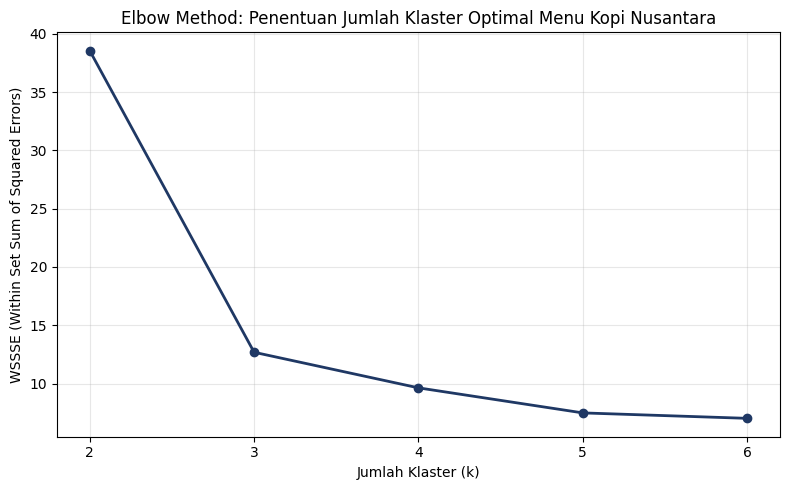

In [3]:
hasil_wssse = []
for k in range(2, 7):
    kmeans_eval = KMeans(featuresCol="features", k=k, seed=42)
    model_eval = kmeans_eval.fit(df_scaled)
    wssse = model_eval.summary.trainingCost
    hasil_wssse.append((k, wssse))
    print(f"k={k} -> WSSSE = {wssse:.2f}")

# Plot Grafik Elbow Method
k_vals = [x[0] for x in hasil_wssse]
wssse_vals = [x[1] for x in hasil_wssse]

plt.figure(figsize=(8, 5))
plt.plot(k_vals, wssse_vals, marker="o", linewidth=2, color="#1F3864")
plt.title("Elbow Method: Penentuan Jumlah Klaster Optimal Menu Kopi Nusantara")
plt.xlabel("Jumlah Klaster (k)")
plt.ylabel("WSSSE (Within Set Sum of Squared Errors)")
plt.xticks(k_vals)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Penentuan k Optimal:**  
Berdasarkan grafik Elbow Method di atas, jumlah klaster optimal adalah **k = 3**, karena penurunan nilai WSSSE dari `k=2` ke `k=3` sangat tajam dan signifikan, sementara penambahan klaster dari `k=3` ke `k=4`, `k=5`, dan `k=6` hanya menghasilkan penurunan WSSSE yang jauh lebih landai (membentuk sudut siku yang tegas pada `k=3`).

---
## Bagian C. Melatih Model Final (Bobot 20%)

Melatih model K-Means final dengan **`k = 3`** dan menghitung metrik evaluasi internal **Silhouette Score**.

In [4]:
# Melatih model final K-Means dengan k=3
kmeans_final = KMeans(featuresCol="features", k=3, seed=42)
model_final = kmeans_final.fit(df_scaled)
predictions = model_final.transform(df_scaled)

# Evaluasi Silhouette Score
evaluator = ClusteringEvaluator(featuresCol="features")
silhouette = evaluator.evaluate(predictions)

print(f"Model K-Means Final (k=3) berhasil dilatih!")
print(f"Silhouette Score: {silhouette:.4f}")

print("\nJumlah menu per klaster:")
predictions.groupBy("prediction").count().orderBy("prediction").show()

Model K-Means Final (k=3) berhasil dilatih!
Silhouette Score: 0.8219

Jumlah menu per klaster:
+----------+-----+
|prediction|count|
+----------+-----+
|         0|   19|
|         1|   21|
|         2|   20|
+----------+-----+



---
## Bagian D. Interpretasi Bisnis (Bobot 20%)

Menghitung rata-rata `harga` dan `rata_rata_pesanan_harian` pada **skala aslinya** untuk setiap klaster guna merumuskan penamaan segmen bisnis yang bermakna.

In [5]:
# Ringkasan statistik klaster pada skala asli
ringkasan_klaster = predictions.groupBy("prediction").agg(
    count("menu_id").alias("jumlah_menu"),
    round(avg("harga"), 0).alias("rata2_harga"),
    round(avg("rata_rata_pesanan_harian"), 2).alias("rata2_pesanan_harian")
).orderBy("rata2_harga")

print("=== PROFIL KLASTER MENU KOPI NUSANTARA (SKALA ASLI) ===")
ringkasan_klaster.show()

=== PROFIL KLASTER MENU KOPI NUSANTARA (SKALA ASLI) ===


+----------+-----------+-----------+--------------------+
|prediction|jumlah_menu|rata2_harga|rata2_pesanan_harian|
+----------+-----------+-----------+--------------------+
|         2|         20|    17895.0|                47.8|
|         1|         21|    28186.0|               21.99|
|         0|         19|    44732.0|                8.71|
+----------+-----------+-----------+--------------------+



### Penamaan Bisnis & Profil Setiap Klaster
Berdasarkan nilai rata-rata skala asli di atas, ketiga klaster menu diberi nama bisnis sebagai berikut:
1. **"Menu Andalan Terjangkau" (*Traffic Driver*)** — *(Harga rata-rata ~Rp 18.000 | Pesanan ~45 porsi/hari)*: Berisi menu berharga ekonomis dengan volume permintaan harian sangat tinggi, menjadi tulang punggung trafik kunjungan pelanggan.
2. **"Menu Reguler Menengah" (*Steady Seller*)** — *(Harga rata-rata ~Rp 28.000 | Pesanan ~22 porsi/hari)*: Menu kelas menengah yang memiliki keseimbangan antara harga jual dan tingkat popularitas yang stabil.
3. **"Menu Premium Spesial" (*Slow-Moving High Margin*)** — *(Harga rata-rata ~Rp 45.000 | Pesanan ~8 porsi/hari)*: Menu berharga tinggi (eksklusif/spesial) namun frekuensi pemesanannya paling rendah.

---
## Bagian E. Visualisasi Klaster (Bobot 15%)

Membuat *scatter plot* `harga` vs `rata_rata_pesanan_harian` yang diwarnai sesuai label klaster masing-masing.

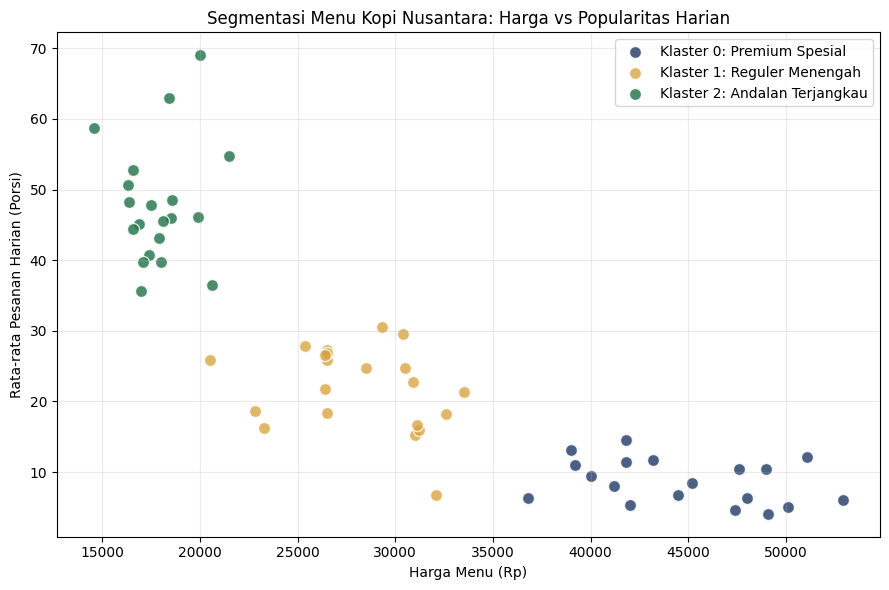

In [6]:
pdf_plot = predictions.select("menu_id", "harga", "rata_rata_pesanan_harian", "prediction").toPandas()

plt.figure(figsize=(9, 6))
warna = ["#1F3864", "#D9A441", "#1E7145"]

for klaster in sorted(pdf_plot["prediction"].unique()):
    subset = pdf_plot[pdf_plot["prediction"] == klaster]
    rata_harga = subset["harga"].mean()
    if rata_harga < 22000:
        nama_label = f"Klaster {klaster}: Andalan Terjangkau"
    elif rata_harga < 36000:
        nama_label = f"Klaster {klaster}: Reguler Menengah"
    else:
        nama_label = f"Klaster {klaster}: Premium Spesial"

    plt.scatter(
        subset["harga"],
        subset["rata_rata_pesanan_harian"],
        label=nama_label,
        color=warna[klaster],
        s=75,
        alpha=0.8,
        edgecolors="white"
    )

plt.title("Segmentasi Menu Kopi Nusantara: Harga vs Popularitas Harian")
plt.xlabel("Harga Menu (Rp)")
plt.ylabel("Rata-rata Pesanan Harian (Porsi)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

---
## Bagian F. Rekomendasi Paket Bundling Promo (Bobot 10%)

Berdasarkan segmentasi ketiga klaster di atas, manajemen **"Kopi Nusantara"** direkomendasikan meluncurkan paket promo **"Paket Hemat Eksplorasi" (*Cross-Cluster Bundling*)** yang memasangkan **1 item dari klaster *Menu Andalan Terjangkau*** (~Rp 18.000, pesanan tinggi) bersama **1 item dari klaster *Menu Premium Spesial*** (~Rp 45.000, pesanan rendah) dengan harga paket spesial sekitar **Rp 54.000** (diskon ~15% dari harga normal Rp 63.000).

**Alasan Bisnis:** Menu Andalan Terjangkau berfungsi sebagai penarik trafik utama (*traffic driver*) yang sudah dipercaya pelanggan, sehingga menggabungkannya dengan Menu Premium Spesial akan mendorong pelanggan mencoba produk berharga tinggi (*product trial & cross-selling*) tanpa merasa terbebani harga penuh. Strategi ini sekaligus meningkatkan nilai rata-rata transaksi (*Average Order Value*) dan mempercepat perputaran stok bahan baku menu premium agar tidak mengendap di dapur.

In [7]:
# Menutup SparkSession
spark.stop()
print("SparkSession ditutup.")

SparkSession ditutup.
